# Model Evaluation

In this phase, we evaluate the performance of the trained models using the predictions generated in Phase 8.

The evaluation focuses on:
- Delivery delay prediction (classification)
- Shipment cost prediction (regression)

No model training is performed in this phase.

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, r2_score

import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load Model Results

Load the saved predictions from Phase 8.

In [2]:

from pathlib import Path

BASE = Path.cwd()

# Support running from the project root or notebooks/ folder
if not (BASE / "data").is_dir():
    if (BASE.parent / "data").is_dir():
        BASE = BASE.parent
    else:
        raise FileNotFoundError(
            "Project data folder not found. "
            "Run this notebook from the project root or notebooks folder."
        )

RAW = BASE / "data" / "raw"
PROC = BASE / "data" / "processed"
DB = BASE / "data" / "logistics.db"

# Create only the directory needed for processed datasets
PROC.mkdir(parents=True, exist_ok=True)

print("Project root:", BASE)
print("Raw data:", RAW)
print("Processed data:", PROC)


results = pd.read_csv(PROC / "final_model_results.csv")

results.head()

Project root: d:\Athar\LogiTech_Logistics_Analysis
Raw data: d:\Athar\LogiTech_Logistics_Analysis\data\raw
Processed data: d:\Athar\LogiTech_Logistics_Analysis\data\processed


,Actual_Delivery,Predicted_Delivery,Actual_Cost,Predicted_Cost
0,0,0,-0.028343,-0.130549
1,0,0,-0.034099,0.090124
2,0,0,-0.028343,-0.144932
3,0,0,-0.028343,-0.142668
4,0,0,-0.028343,-0.173167


## 2. Delivery Delay Prediction Evaluation

Evaluate how well the model predicts delayed and on-time shipments.

In [3]:
y_test = results["Actual_Delivery"]
y_pred = results["Predicted_Delivery"]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9544221378187737

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98      1756
           1       0.80      0.05      0.09        87

    accuracy                           0.95      1843
   macro avg       0.88      0.52      0.53      1843
weighted avg       0.95      0.95      0.93      1843



## 3. Confusion Matrix

Visualize correct and incorrect predictions.

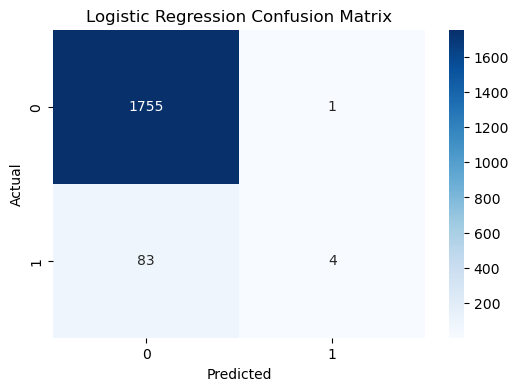

In [4]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

## 4. Shipment Cost Prediction Evaluation

Evaluate how well the model predicts shipment cost.

In [5]:
y_test_reg = results["Actual_Cost"]
y_pred_reg = results["Predicted_Cost"]

r2 = r2_score(y_test_reg, y_pred_reg)

print("R2 Score (Shipment Cost Model):", round(r2, 4))

R2 Score (Shipment Cost Model): -46.0877


## 5. Evaluation Summary

- The delivery prediction model shows high overall accuracy.
- Most on-time shipments are correctly identified.
- Delayed shipments are harder to detect, indicating class imbalance.
- The shipment cost model shows very low accuracy.
- This suggests that important factors affecting cost are missing from the data.

Overall, the model performs well for general delivery patterns but requires improvement for detecting delays and predicting shipment cost accurately.